# `rioxarray`

In this lesson we will introduce [`rioxarray`](https://corteva.github.io/rioxarray/stable/), a Python extension for `xarray` to manipulate `xarray.DataArray`s as rasters. 

The name `rioxarray` stands for *raster input/output + xarray*. 

## About the data
The raster files we will use today come from the [US National Agriculture Imagery Program (NAIP)](https://naip-usdaonline.hub.arcgis.com). 
NAIP images are are high-resolution aerial images with four spectral bands: red (R), green (G), blue (B) and near-infrared (NIR). 
The raster's we'll use today are from 2020.

The data used in this lesson was pre-processing from a complete NAIP scene to separate the RGB bands from the NIR band and reduce the spatial extent. 
The data was accessed through [Microsoft's Planetary Computer NAIP data repository](https://planetarycomputer.microsoft.com/dataset/naip#overview).

## Import a TIF file

Let's start by loading the libraries we will use: 

In [2]:
import os

import numpy as np
import matplotlib.pyplot as plt

import geopandas as gpd

import rioxarray as rioxr

There are [multiple ways of opening a TIF file using `xarray` or `rioxarray`](https://corteva.github.io/rioxarray/html/getting_started/getting_started.html). 
Using the `rioxarray.open_rasterio()` function to open the TIF file is a simple way to import the raster file as an `xarray.DataArray` and make sure all our geospatial data gets loaded correctly:

In [3]:
# Import NIR TIF file
fp = os.path.join('data','NAIP_SB_nir.tif')
nir = rioxr.open_rasterio(fp)
nir

<xarray.DataArray (band: 1, y: 3208, x: 2419)> Size: 8MB
[7760152 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [4]:
# Access attributes directly
print(f'Shape: {nir.shape}')
print(f'Data type: {nir.dtype}')

Shape: (1, 3208, 2419)
Data type: uint8


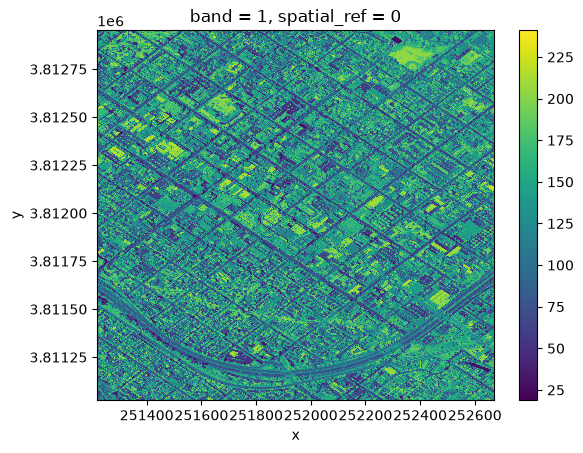

In [5]:
nir.plot()

## Drop a dimension

The raster has an unnecessary extra dimension: band.

It is unnecessary because we only have one band, therefore it is redundant.

In [7]:
print('Sizes of dimensions:',dict(nir.sizes)) # number of values along each axis

Sizes of dimensions: {'band': 1, 'y': 3208, 'x': 2419}


- 'band' has length 1, therefore it makes the `xarray` 3-dimensional for no reason
- `squeeze` removes a dimension of length 1
- `drop = True` remove the coordinates for that dimension

In [10]:
# Original dimensions and coordinates
print(nir.dims, nir.coords,'\n')

# Remove length 1 dimension (band) and its coordinates
nir = nir.squeeze('band', drop = True)
print(nir.dims, nir.coords,'\n')


('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 

('y', 'x') Coordinates:
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 



## `rio` accessor

In [11]:
# Examine raster attributes using rio accessor
print('Number of bands', nir.rio.count)
print('Height', nir.rio.height)
print('Weight', nir.rio.width, '\n')

print('Spatial bounding box: ')
print(nir.rio.bounds(), '\n')

print('CRS: ', nir.rio.crs)

Number of bands 1
Height 3208
Weight 2419 

Spatial bounding box: 
(251218.8, 3811027.2, 252670.19999999998, 3812952.0) 

CRS:  EPSG:26911


## Multi-band raster

In [12]:
# import RGB TIF file
fp = os.path.join('data','NAIP_SB_rgb.tif')
rgb = rioxr.open_rasterio(fp)
rgb

<xarray.DataArray (band: 3, y: 3208, x: 2419)> Size: 23MB
[23280456 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [13]:
print('Shape:',rgb.shape)
print('Number of bands:',rgb.rio.count)
print('Data type:',rgb.dtype)
print('CRS:',rgb.rio.crs)

Shape: (3, 3208, 2419)
Number of bands: 3
Data type: uint8
CRS: EPSG:26911


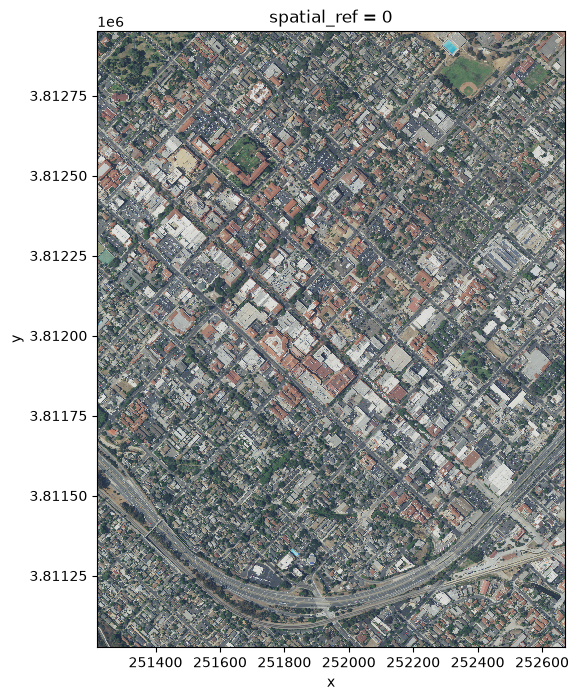

In [ ]:
# Plot three bands as RBG image
rgb_aspect_ratio = rgb.rio.width / rgb.rio.height # raster's aspect ratio
rgb.plot.imshow(figsize=(8*rgb_aspect_ratio,8)) # multiply by the aspect ratio to get the actual dimension of the raster

## Clip a raster

Our area of interest (AOI) for this lesson is a smaller region that includes only a few blocks around the NCEAS building. This is outlined in a GeoJSON file:

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

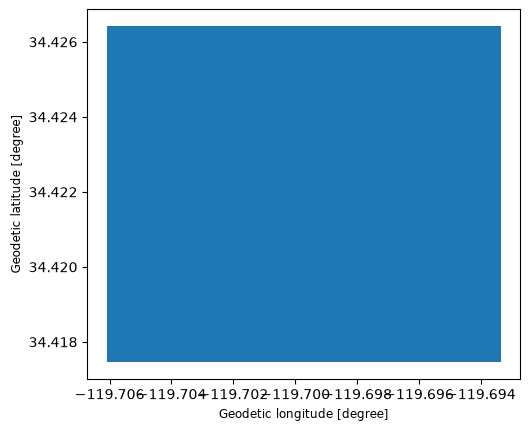

In [17]:
fp = os.path.join('data', 'SB_aoi.geojson')
aoi = gpd.read_file(fp)
aoi.plot()

In [18]:
# Examine the CRS
print('aoi CRS:',aoi.crs)
print('nir CRS:',nir.rio.crs)
print('rgb CRS:',rgb.rio.crs)

aoi CRS: EPSG:4326
nir CRS: EPSG:26911
rgb CRS: EPSG:26911


In [19]:
# Reproject AOI to RBG CRS
aoi = aoi.to_crs(rgb.rio.crs)

assert aoi.crs == rgb.rio.crs

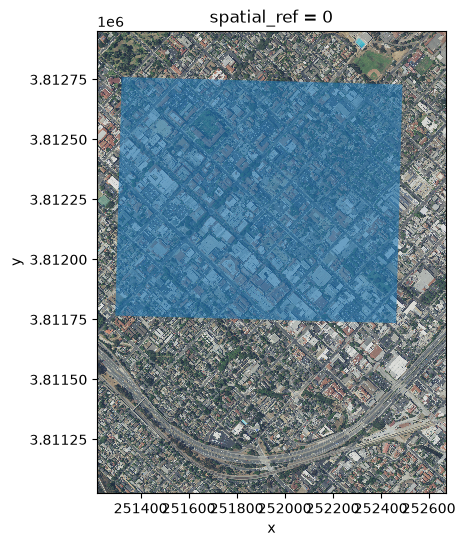

In [20]:
# Plot RGB raster with AOI overlay

fig, ax = plt.subplots(figsize=(6*rgb_aspect_ratio, 6))

rgb.plot.imshow(ax=ax)

aoi.plot(ax=ax,
         alpha = 0.6)

plt.show()

In [21]:
aoi.total_bounds

array([ 251294.31339082, 3811734.95697039,  252490.65041356,
       3812760.09703315])

In [23]:
rgb_small = rgb.rio.clip_box(*aoi.total_bounds) # add asterisk to unpack the array

In [24]:
nir_small = nir.rio.clip_box(*aoi.total_bounds)

Original shape: (3208, 2419)
Clipped shape: (1710, 1995)


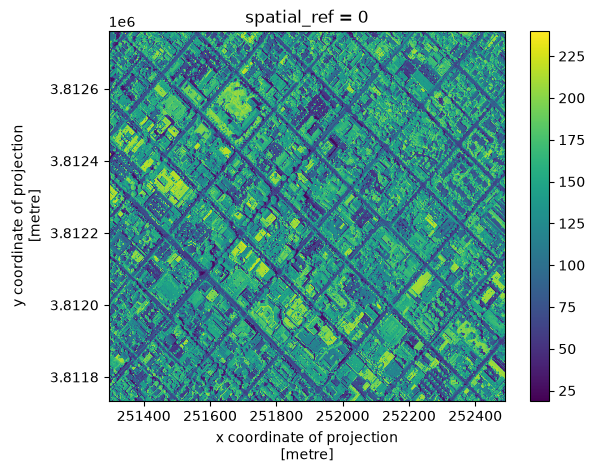

In [25]:
# Examine clipped data
print('Original shape:', nir.shape)
print('Clipped shape:', nir_small.shape)

nir_small.plot()

## Raster Math

We will compute the **Normalized Difference Vegetation Index (NDVI)** over our AOI

NDVI checks whether an area has live green vegetation.
- always between -1 and 1: 
    - values about 0.6 correspond to lush vegetation
    - water, roofs, pavements, close to zero or negative
    - sand, rock, snow are 0.1 and below
    - generally, above 0.1 is vegetation


NDVI uses the NIR and red bands:
$$NDVI = \frac{NIR-red}{NIR+red}$$

In [26]:
# Select dimension by name and coordinate by label
red_small = rgb_small.sel(band=1)
red_small

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [28]:
ndvi = (nir_small - red_small)/(nir_small + red_small)
ndvi

<xarray.DataArray (y: 1710, x: 1995)> Size: 27MB
array([[           inf, 3.37500000e+00, 9.25000000e+00, ...,
        5.85000000e+01, 1.18811881e+00, 2.46913580e-02],
       [2.93650794e-01,            inf, 2.88888889e+00, ...,
        3.50000000e+00, 2.35000000e+02, 6.54205607e-02],
       [3.20158103e-01, 3.23076923e-01, 3.49112426e-01, ...,
        4.32203390e+00, 1.66666667e-01, 5.28571429e+00],
       ...,
       [3.96039604e-02, 1.06779661e+00, 9.76470588e-01, ...,
        3.63492063e+00, 4.22222222e+00, 8.70370370e+00],
       [1.06521739e+01, 9.92156863e-01, 8.06451613e-03, ...,
        4.10714286e+00, 3.69696970e+00, 2.14018692e+00],
       [1.10869565e+01, 6.83783784e+00, 0.00000000e+00, ...,
        3.93750000e+00, 1.95934959e+00, 1.51282051e+00]],
      shape=(1710, 1995))
Coordinates:
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
    band         int64 8B 1

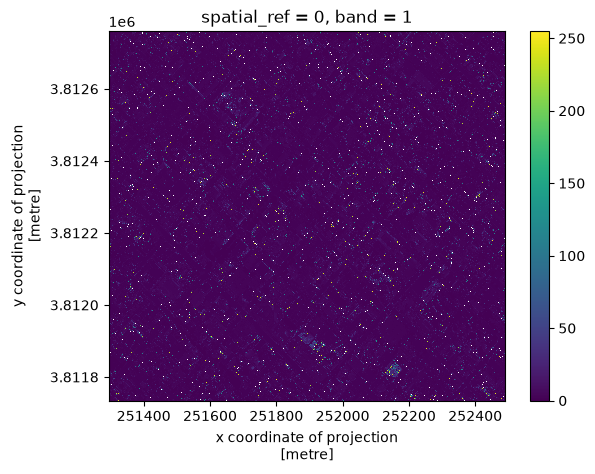

In [29]:
ndvi.plot()

- Values are not between -1 and 1
- Still 3-dimensional
- Datatype issue: cannot hold negative values